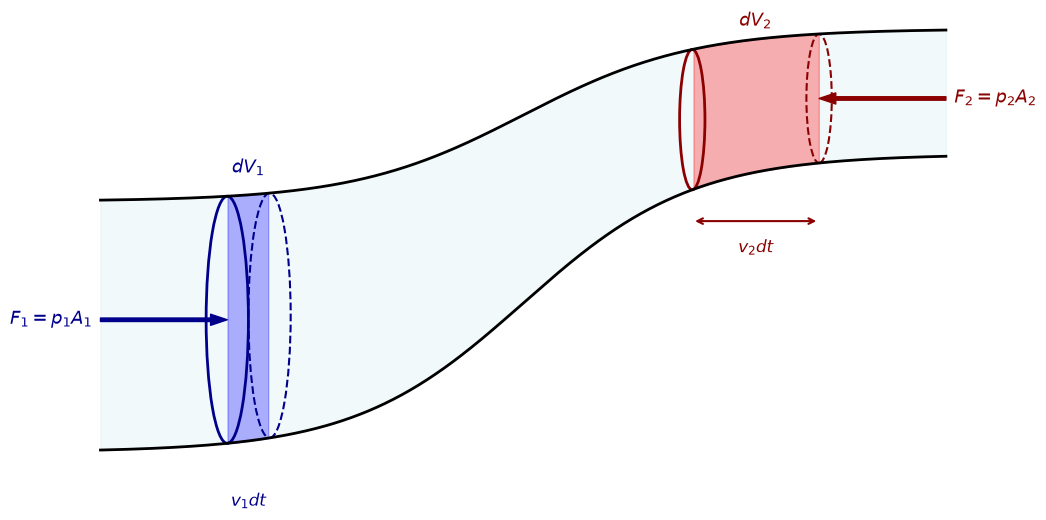

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

# Funzioni per il profilo del tubo (variazione di altezza e restringimento)
def altezza_centro(x):
    return 3.0 + 1.5 * np.tanh(x / 2)

def raggio_tubo(x):
    return 1.2 - 0.4 * np.tanh(x / 2)

x = np.linspace(-5, 5, 500)
Z = altezza_centro(x)
R = raggio_tubo(x)

# Calcolo delle pareti superiore e inferiore
parete_sup = Z + R
parete_inf = Z - R

# ==========================================
# GRAFICO: BERNOULLI CON ELEMENTI DI VOLUME
# ==========================================
fig, ax = plt.subplots(figsize=(12, 6))

# Disegna le pareti del tubo principale
ax.plot(x, parete_sup, color='black', linewidth=2)
ax.plot(x, parete_inf, color='black', linewidth=2)

# Sfondo del fluido generico
ax.fill_between(x, parete_inf, parete_sup, color='lightblue', alpha=0.15)

# Definizione delle posizioni x1 e x2 e dei relativi dxt (spostamenti v*dt)
# Scegliamo dx2 > dx1 perché il tubo si restringe e la velocità aumenta
x1, dx1 = -3.5, 0.5
x2, dx2 = 2.0, 1.5  

# Calcolo geometrico dei punti di ingresso e uscita dei volumetti
z1, r1 = altezza_centro(x1), raggio_tubo(x1)
z1_end = altezza_centro(x1 + dx1)
r1_end = raggio_tubo(x1 + dx1)

z2, r2 = altezza_centro(x2), raggio_tubo(x2)
z2_end = altezza_centro(x2 + dx2)
r2_end = raggio_tubo(x2 + dx2)

# Evidenzia ed colora i volumi dV1 (sinistra) e dV2 (destra)
idx1 = (x >= x1) & (x <= x1 + dx1)
ax.fill_between(x[idx1], parete_inf[idx1], parete_sup[idx1], color='blue', alpha=0.3)

idx2 = (x >= x2) & (x <= x2 + dx2)
ax.fill_between(x[idx2], parete_inf[idx2], parete_sup[idx2], color='red', alpha=0.3)

# Disegna i profili ellittici delle sezioni d'ingresso e d'uscita dei volumetti
ax.add_patch(Ellipse((x1, z1), width=0.5, height=2*r1, edgecolor='darkblue', facecolor='none', linewidth=2))
ax.add_patch(Ellipse((x1+dx1, z1_end), width=0.5, height=2*r1_end, edgecolor='darkblue', facecolor='none', linewidth=1.5, linestyle='--'))

ax.add_patch(Ellipse((x2, z2), width=0.3, height=2*r2, edgecolor='darkred', facecolor='none', linewidth=2))
ax.add_patch(Ellipse((x2+dx2, z2_end), width=0.3, height=2*r2_end, edgecolor='darkred', facecolor='none', linewidth=1.5, linestyle='--'))

# ==========================================
# ANNOTAZIONI: Forze di pressione e Spostamenti
# ==========================================

# Forze di pressione applicate alle facce esterne dei volumetti
ax.annotate('', xy=(x1, z1), xytext=(x1 - 1.5, z1),
            arrowprops=dict(facecolor='darkblue', edgecolor='darkblue', width=2.5, headwidth=8))
ax.text(x1 - 1.6, z1, '$F_1 = p_1 A_1$', fontsize=13, color='darkblue', ha='right', va='center')

ax.annotate('', xy=(x2 + dx2, z2_end), xytext=(x2 + dx2 + 1.5, z2_end),
            arrowprops=dict(facecolor='darkred', edgecolor='darkred', width=2.5, headwidth=8))
ax.text(x2 + dx2 + 1.6, z2_end, '$F_2 = p_2 A_2$', fontsize=13, color='darkred', ha='left', va='center')

# Quote dello spostamento spaziale (v * dt) sotto il tubo
y_line1 = z1 - r1 - 0.4
ax.annotate('', xy=(x1, y_line1), xytext=(x1 + dx1, y_line1), arrowprops=dict(arrowstyle='<->', color='darkblue', lw=1.5))
ax.text(x1 + dx1/2, y_line1 - 0.4, '$v_1 dt$', fontsize=12, ha='center', color='darkblue')

y_line2 = z2 - r2 - 0.4
ax.annotate('', xy=(x2, y_line2), xytext=(x2 + dx2, y_line2), arrowprops=dict(arrowstyle='<->', color='darkred', lw=1.5))
ax.text(x2 + dx2/2, y_line2 - 0.4, '$v_2 dt$', fontsize=12, ha='center', color='darkred')

# Etichette dei volumi dV sopra il tubo
ax.text(x1 + dx1/2, z1 + r1 + 0.3, '$dV_1$', fontsize=13, ha='center', color='darkblue', weight='bold')
ax.text(x2 + dx2/2, z2 + r2 + 0.3, '$dV_2$', fontsize=13, ha='center', color='darkred', weight='bold')

# Pulizia assi e titolo
ax.axis('off')
# Salvataggio file
fig.savefig('../../Appunti/img/teorema_bernoulli_vdt.png', dpi=300, bbox_inches='tight')
plt.show()